In [ ]:
!pip install python-dotenv huggingface-hub llama-index transformers sentence-transformers llama-index-llms-huggingface llama-index-embeddings-huggingface pdfplumber llama-index-llms-openrouter llama-index-retrievers-bm25 tabula-py  jpype1 pystemmer

## 1. Setup & Configuration
In this section, we set up the necessary dependencies, including third-party libraries and API keys.
We also configure the language models (LLMs) and embedding models used throughout the tutorial.

Key Steps:
- Import required Python libraries.
- Load API keys securely from environment variables.
- Initialize the OpenRouter LLMs for both querying and evaluation.
- Set up the HuggingFace embedding model for text representation.
- Apply `nest_asyncio` to handle event loop issues in Jupyter environments.


In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3" # Suppresses TensorFlow warnings
from dotenv import load_dotenv
import Stemmer
import nest_asyncio
import tabula
import pandas as pd
from dotenv import load_dotenv
from llama_index.core import Document
from llama_index.core import (SimpleDirectoryReader, VectorStoreIndex, Settings)
from llama_index.embeddings.huggingface import HuggingFaceEmbedding
from llama_index.llms.openrouter import OpenRouter
import asyncio


load_dotenv()  # reads OPENROUTER_API_KEY from a local .env file (never commit it)
api_key = os.getenv("OPENROUTER_API_KEY")
if not api_key:
    raise ValueError("OPENROUTER_API_KEY not found. Copy .env.example to .env and add your key.")


# Initialize OpenRouter LLM
#llm = OpenRouter(api_key=api_key, model="mistralai/mistral-7b-instruct", max_tokens=512, context_window=4096)
llm = OpenRouter(api_key=api_key, model="meta-llama/Llama-3.1-8B-Instruct", max_tokens=512, context_window=4096)
Judge_llm = OpenRouter(api_key=api_key, model="qwen/qwen-turbo", max_tokens=512, context_window=4096)
Settings.llm = llm

# Apply nest_asyncio to fix event loop issues in Jupyter
nest_asyncio.apply()

# Set up embedding model
embed_model_name = "sentence-transformers/all-MiniLM-L6-v2"
embed_model = HuggingFaceEmbedding(model_name=embed_model_name)
Settings.embed_model = embed_model

## 2. Document Loading & Preprocessing
Here, we load the syllabus document from a PDF file and process it for retrieval.

Key Steps:
- Read the syllabus PDF and extract its textual content.
- Extract tabular data from the PDF using `tabula`.
- Convert the extracted table data into text format.
- Combine the extracted text and tables into a unified document.
- Define an ingestion pipeline to preprocess text by splitting it into manageable chunks and applying embeddings.


In [2]:
import warnings
import logging
warnings.filterwarnings("ignore")
logging.getLogger().setLevel(logging.ERROR)

for name in [
    "llama_index", "httpx", "openai","urllib3","tabula", "py4j",
]:
    logging.getLogger(name).setLevel(logging.ERROR)

In [3]:
import re
from llama_index.core import Document

# Load Course Syllabus Document
#pdf_path = "./Syllabus.pdf"
pdf_path = "./WebMD.pdf"
documents = SimpleDirectoryReader(input_files=[pdf_path]).load_data()

# Convert table data into an additional Document
tables = tabula.read_pdf(pdf_path, pages="all", force_subprocess=True)
table_docs = [df.to_markdown(index=False) for df in tables]
all_tables_text = "\n\n".join(table_docs)
document_from_tables = Document(text=all_tables_text)

documents = documents + [document_from_tables]

# PDF TEXT CLEANING STEP
def clean_pdf_text(t: str) -> str:
    t = re.sub(r"/gid\d+", "", t) 
    t = re.sub(r"(\w)-\s*\n(\w)", r"\1\2", t) 
    t = re.sub(r"\n{3,}", "\n\n", t) 
    t = re.sub(r"[ \t]{2,}", " ", t) 
    return t.strip()

documents = [
    Document(text=clean_pdf_text(d.text), metadata=d.metadata)
    for d in documents
]

# pipeline with transformations
from llama_index.core.node_parser import SentenceSplitter, TokenTextSplitter
from llama_index.core.ingestion import IngestionPipeline

pipeline = IngestionPipeline(
    transformations=[
        TokenTextSplitter(
            separator="\n\n",
            chunk_size=512,
            chunk_overlap=100
        ),
        embed_model
    ]
)
nodes = pipeline.run(documents=documents)

In [4]:
def is_noise_node(n):
    t = n.get_content().lower()
    return (
        "vyepti" in t or "eptinezumab" in t
        or ("headache types" in t and "table" in t)
    )

filtered_nodes = [n for n in nodes if not is_noise_node(n)]
print("nodes:", len(nodes), "filtered:", len(filtered_nodes))

nodes: 17 filtered: 13


## 3. Indexing & Retrieval
Once the document is processed, we create multiple retrievers for efficient information retrieval.

Key Steps:
- Build a `VectorStoreIndex` from the preprocessed document chunks.
- Implement different retrieval methods:
  - **Base Retriever:** Retrieves the most relevant document chunk.
  - **AutoMerging Retriever:** Aggregates multiple related chunks before returning results.
  - **BM25 Retriever:** Uses term frequency-based ranking (a traditional information retrieval method).
  - **Hybrid Fusion Retriever:** (Task 4)
- Define retrieval hyperparameters, such as similarity threshold and number of top results to return.


In [5]:
from llama_index.core.retrievers import AutoMergingRetriever
from llama_index.retrievers.bm25 import BM25Retriever
from llama_index.core.retrievers import QueryFusionRetriever

# Vector Index and Query Engine
index = VectorStoreIndex(nodes)
query_engine = index.as_query_engine()

base_retriever = index.as_retriever(similarity_top_k=3)
auto_base_retriever = index.as_retriever(similarity_top_k=3)
auto_merging_retriever = AutoMergingRetriever(auto_base_retriever, index.storage_context)
bm25_retriever = BM25Retriever.from_defaults(nodes=nodes, similarity_top_k=2, stemmer=Stemmer.Stemmer("english"), language="english")

# Create Hybrid Fusion Retriever (Task 4)
vector_retriever_fusion = index.as_retriever(similarity_top_k=8)
bm25_retriever_fusion = BM25Retriever.from_defaults(
    nodes=nodes,
    similarity_top_k=8,
    stemmer=Stemmer.Stemmer("english"),
    language="english"
)

# Hybrid fusion (0.6 vector + 0.4 bm25)
fusion_retriever = QueryFusionRetriever(
    retrievers=[vector_retriever_fusion, bm25_retriever_fusion],
    mode="relative_score",       # weights are only applied in a score-based fusion mode
    retriever_weights=[0.6, 0.4],  # 0.6 vector, 0.4 BM25
    similarity_top_k=3,   
    num_queries=1        
)

from llama_index.core.query_engine import RetrieverQueryEngine
from llama_index.core.evaluation import RetrieverEvaluator

fusion_query_engine = RetrieverQueryEngine.from_args(fusion_retriever)

fusion_retriever_evaluator = RetrieverEvaluator.from_metric_names(
    ["mrr", "hit_rate", "precision", "recall"],
    retriever=fusion_retriever
)

## 4. Query Engines & Evaluation Setup
In this section, we configure the query engines and set up evaluation metrics to assess retriever performance.

Key Steps:
- Instantiate query engines for each retrieval method to allow direct querying.
- Define evaluation models to measure:
  - **Faithfulness:** Whether the retrieved information is accurate and grounded in the original document.
  - **Relevancy:** Whether the retrieved information is relevant to the query.
- Configure different retriever evaluators to assess retrieval effectiveness using metrics such as:
  - Mean Reciprocal Rank (MRR)
  - Hit Rate
  - Precision
  - Recall


In [6]:
# query engines
from llama_index.core.query_engine import RetrieverQueryEngine
from llama_index.core.evaluation import FaithfulnessEvaluator, RelevancyEvaluator, RetrieverEvaluator

base_query_engine = RetrieverQueryEngine.from_args(base_retriever)
auto_query_engine = RetrieverQueryEngine.from_args(auto_merging_retriever)
bm25_query_engine = RetrieverQueryEngine.from_args(bm25_retriever)

faithfulness_evaluator = FaithfulnessEvaluator(llm=Judge_llm)
relevancy_evaluator = RelevancyEvaluator(llm=Judge_llm)

base_retriever_evaluator = RetrieverEvaluator.from_metric_names(["mrr", "hit_rate", "precision", "recall"], retriever=base_retriever)
auto_retriever_evaluator = RetrieverEvaluator.from_metric_names(["mrr", "hit_rate", "precision", "recall"], retriever=auto_merging_retriever)
bm25_retriever_evaluator = RetrieverEvaluator.from_metric_names(["mrr", "hit_rate", "precision", "recall"], retriever=bm25_retriever)

## 5. Preparing Evaluation Questions & Display Functions

In this section, we define a set of evaluation questions to systematically assess the performance of different retrieval methods. Additionally, we create utility functions for displaying results in a structured and readable format.

Key Steps:
- Define a set of test queries (e.g., syllabus-related questions).
- Generate question-context pairs for automated evaluation.

To make evaluation results more interpretable, we define:
- **`displayify_df(df)`**: A helper function to format and display DataFrames neatly in Jupyter notebooks.
- **`display_retriever_eval_results(name, eval_results)`**: Computes and prints key retrieval evaluation metrics.

In [7]:
from llama_index.core.evaluation import QueryResponseDataset, generate_question_context_pairs, EmbeddingQAFinetuneDataset
# Use Evaluation Questions
#eval_questions = []
#with open('eval_questions.txt', 'r') as file:
# for line in file:
 # eval_questions.append(line.strip())

# Add more evaluation questions
#eval_questions = [
 # "How can a student request a regrade?",
  # "What topic is covered in Week 3?",
   # "What's happening on Feb 17?"
#]

eval_questions = [
    "What are common symptoms of chronic migraine?",
    "What treatments are mentioned for chronic migraine?",
    "What are possible triggers or risk factors discussed?"
]

qa_dataset = generate_question_context_pairs(nodes=nodes, llm=llm, num_questions_per_chunk=1)
qa_dataset.save_json("qa_dataset_webmd_new.json")

#qa_dataset = QueryResponseDataset.from_json("./qa_dataset_webmd_new.json")
#qa_dataset = EmbeddingQAFinetuneDataset.from_json("./qa_dataset_webmd_new.json")

# Pretty Display Function
def displayify_df(df):
    """For pretty displaying DataFrame in a notebook."""
    display_df = df.style.set_properties(
        **{
            "inline-size": "300px",
            "overflow-wrap": "break-word",
        }
    )
    display(display_df)

# Helper to display retrieval metrics
def display_retriever_eval_results(name, eval_results):
    """Build a small DataFrame summarizing retrieval metrics across queries."""
    print(f"=== {name} ===")
    metric_dicts = [res.metric_vals_dict for res in eval_results]
    if not metric_dicts:
        print("No retriever metrics found!")
        return
    df = pd.DataFrame(metric_dicts)
    #displayify_df(df)
    print("Mean:\n", df.mean(numeric_only=True), "\n")

## 6. Running Evaluations & Comparing Retrievers
Finally, we conduct retrieval evaluations and compare the effectiveness of different retrieval strategies.

Key Steps:
- Execute retrieval on all retrievers (Base, AutoMerging, BM25, Hybrid Fusion).
- Assess each retriever's faithfulness and relevancy scores.
- Compare retrieval results by averaging the evaluation metrics.
- Display results in tabular format for easy comparison.

This step helps determine which retrieval method performs best for a given dataset.


In [8]:
import asyncio

async def run_evaluation():
    eval_results = []

    for query in eval_questions:
        base_response = base_query_engine.query(query)
        auto_response = auto_query_engine.query(query)
        bm25_response = bm25_query_engine.query(query)

        fusion_response = fusion_query_engine.query(query)
        fusion_text = fusion_response.response
        fusion_contexts = "\n".join([node.get_content() for node in fusion_response.source_nodes])

        fusion_faithfulness = faithfulness_evaluator.evaluate_response(response=fusion_response)
        fusion_relevancy = relevancy_evaluator.evaluate_response(query=query, response=fusion_response)

        base_text = base_response.response
        auto_text = auto_response.response
        bm25_text = bm25_response.response

        base_contexts = "\n".join([node.get_content() for node in base_response.source_nodes])
        auto_contexts = "\n".join([node.get_content() for node in auto_response.source_nodes])
        bm25_contexts = "\n".join([node.get_content() for node in bm25_response.source_nodes])

        base_faithfulness = faithfulness_evaluator.evaluate_response(response=base_response)
        auto_faithfulness = faithfulness_evaluator.evaluate_response(response=auto_response)
        bm25_faithfulness = faithfulness_evaluator.evaluate_response(response=bm25_response)

        base_relevancy = relevancy_evaluator.evaluate_response(query=query, response=base_response)
        auto_relevancy = relevancy_evaluator.evaluate_response(query=query, response=auto_response)
        bm25_relevancy = relevancy_evaluator.evaluate_response(query=query, response=bm25_response)

        eval_results.append({
            "Query": query,
            "Base Response": base_text,
            "Auto-Merged Response": auto_text,
            "BM25 Response": bm25_text,
            "Base Context": "".join(base_contexts[:100]) + "... " + "".join(base_contexts[-100:]),
            "Auto Context": "".join(auto_contexts[:100]) + "... " + "".join(auto_contexts[-100:]),
            "BM25 Context": "".join(bm25_contexts[:100]) + "... " + "".join(bm25_contexts[-100:]),
            "Base Faithfulness": base_faithfulness.score,
            "Auto Faithfulness": auto_faithfulness.score,
            "BM25 Faithfulness": bm25_faithfulness.score,
            "Base Relevancy": base_relevancy.score,
            "Auto Relevancy": auto_relevancy.score,
            "BM25 Relevancy": bm25_relevancy.score,
            "Fusion Response": fusion_text,
            "Fusion Context": "".join(fusion_contexts[:100]) + "... " + "".join(fusion_contexts[-100:]),
            "Fusion Faithfulness": fusion_faithfulness.score,
            "Fusion Relevancy": fusion_relevancy.score,
        })

    df = pd.DataFrame(eval_results)

    print("\nFaithfulness Comparison")
    print(f"Base Retriever: {df['Base Faithfulness'].mean():.4f}")
    print(f"Auto-Merging Retriever: {df['Auto Faithfulness'].mean():.4f}")
    print(f"BM25 Retriever: {df['BM25 Faithfulness'].mean():.4f}")
    print(f"Fusion Retriever: {df['Fusion Faithfulness'].mean():.4f}")

    print("\nRelevancy Comparison")
    print(f"Base Retriever: {df['Base Relevancy'].mean():.4f}")
    print(f"Auto-Merging Retriever: {df['Auto Relevancy'].mean():.4f}")
    print(f"BM25 Retriever: {df['BM25 Relevancy'].mean():.4f}")
    print(f"Fusion Retriever: {df['Fusion Relevancy'].mean():.4f}")

    base_eval_results = await base_retriever_evaluator.aevaluate_dataset(qa_dataset)
    auto_eval_results = await auto_retriever_evaluator.aevaluate_dataset(qa_dataset)
    bm25_eval_results = await bm25_retriever_evaluator.aevaluate_dataset(qa_dataset)
    fusion_eval_results = await fusion_retriever_evaluator.aevaluate_dataset(qa_dataset)

    print("=== Retrieval Metrics Comparison ===")
    display_retriever_eval_results("Base Retriever", base_eval_results)
    display_retriever_eval_results("Auto-Merging Retriever", auto_eval_results)
    display_retriever_eval_results("BM25 Retriever", bm25_eval_results)
    display_retriever_eval_results("Fusion Retriever", fusion_eval_results)

    # Display results table
    displayify_df(df)
    return df, base_eval_results, auto_eval_results, bm25_eval_results, fusion_eval_results

# Execute Async Evaluation
#asyncio.run(run_evaluation())
df, base_eval_results, auto_eval_results, bm25_eval_results, fusion_eval_results = await run_evaluation()


Faithfulness Comparison
Base Retriever: 1.0000
Auto-Merging Retriever: 1.0000
BM25 Retriever: 1.0000
Fusion Retriever: 1.0000

Relevancy Comparison
Base Retriever: 0.6667
Auto-Merging Retriever: 1.0000
BM25 Retriever: 0.3333
Fusion Retriever: 0.3333
=== Retrieval Metrics Comparison ===
=== Base Retriever ===
Mean:
 mrr          0.107843
hit_rate     0.176471
precision    0.058824
recall       0.176471
dtype: float64 

=== Auto-Merging Retriever ===
Mean:
 mrr          0.107843
hit_rate     0.176471
precision    0.058824
recall       0.176471
dtype: float64 

=== BM25 Retriever ===
Mean:
 mrr          0.088235
hit_rate     0.117647
precision    0.058824
recall       0.117647
dtype: float64 

=== Fusion Retriever ===
Mean:
 mrr          0.107843
hit_rate     0.176471
precision    0.058824
recall       0.176471
dtype: float64 



,Query,Base Response,Auto-Merged Response,BM25 Response,Base Context,Auto Context,BM25 Context,Base Faithfulness,Auto Faithfulness,BM25 Faithfulness,Base Relevancy,Auto Relevancy,BM25 Relevancy,Fusion Response,Fusion Context,Fusion Faithfulness,Fusion Relevancy
0,What are common symptoms of chronic migraine?,"Chronic migraine can increase the risk of various health conditions, including sleep disorders, cardiovascular disorders, inflammatory conditions, neurological disorders, and gastrointestinal issues. Some common symptoms associated with these conditions include poor sleep quality and duration, insomnia, restless legs syndrome, heart attack, stroke, arthritis, epilepsy, multiple sclerosis, fibromyalgia, nausea, and diarrhea.","Common symptoms of chronic migraine include depression and anxiety, sleep disorders such as sleep apnea, insomnia, and restless legs syndrome, cardiovascular disorders like heart attack and stroke, and gastrointestinal issues like nausea and diarrhea. Additionally, people with chronic migraine may experience poor sleep quality and duration, and may be more likely to have conditions such as fibromyalgia and epilepsy.","Based on the information provided, it appears that migraines are a type of headache that can be classified as a chronic condition. According to the table, common symptoms of migraines include: * Nausea * Vomiting * Photophobia (sensitivity to light) * Phonophobia (sensitivity to sound) These symptoms are listed as aggravating factors for migraines, suggesting that they are commonly experienced by individuals with this condition.","13THIS CONTENT IS CREATED AND CONTROLLED BY WEBMD’S EDITORIAL STAFF | WWW.WEBMD.COM JACOB WACKERHA... ses Dominguez, MD, an assistant professor of neurology at Weill Cornell Medicine in New York City.","13THIS CONTENT IS CREATED AND CONTROLLED BY WEBMD’S EDITORIAL STAFF | WWW.WEBMD.COM JACOB WACKERHA... ses Dominguez, MD, an assistant professor of neurology at Weill Cornell Medicine in New York City.","Important Facts about VYEPTI® (vye-ep’-tee) injection for intravenous use, also known as eptinezumab... e 30 minutes to 7 days N/A • No nausea or vomiting, • No more than one of photophobia or phonophobia",1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,"According to the text, common symptoms of chronic migraine include: * Lacrimation (tearing) * Nasal congestion * Rhinorrhea (runny nose) * Ptosis and/or eyelid edema (drooping eyelid or swelling) * Restlessness/agitation * Nausea * Vomiting * Photophobia (sensitivity to light) * Phonophobia (sensitivity to sound)","Important Facts about VYEPTI® (vye-ep’-tee) injection for intravenous use, also known as eptinezumab... that can be attained.” By Sonya Collins Reviewed by Melinda Ratini, DO, MS, WebMD Medical Reviewer",1.000000,0.000000
1,What treatments are mentioned for chronic migraine?,"Medicine for relief during an attack, medicine to prevent future attacks, nerve stimulation, biofeedback, transcranial magnetic stimulation, acupuncture, over-the-counter or prescription pain relievers, botulinum toxin injection, and CGRP antibody drugs.","The treatments mentioned for chronic migraine include: * Medicine for relief during an attack * Medicine to prevent future attacks * Over-the-counter or prescription pain relievers * Nerve stimulation * Biofeedback * Transcranial magnetic stimulation * Acupuncture * CGRP antibody drugs * Botulinum toxin injection Additionally, the article mentions that people may need to try different combinations of treatments to find what works best for them, and that it's possible to switch or add medications to see if they can get even better results.","Nerve stimulation, biofeedback, transcranial magnetic stimulation, and acupuncture are mentioned as some nondrug options that might help with chronic migraine.","THIS CONTENT IS CREATED AND CONTROLLED BY WEBMD’S EDITORIAL STAFF | WWW.WEBMD.COM 11 hen you have c... like I do my patients, with compas - sion and love. These days, I treat 

In [11]:
q = "What nondrug options might help with chronic migraine?"
resp = fusion_query_engine.query(q)

print("ANSWER:", resp.response)
print("\nTOP SOURCES:")
for i, n in enumerate(resp.source_nodes[:3], 1):
    print(f"\n--- source {i} ---")
    print(n.get_content()[:350])

ANSWER: Nerve stimulation, biofeedback, transcranial magnetic stimulation, and acupuncture.

TOP SOURCES:

--- source 1 ---
Some nondrug options might also help with chronic migraine. 
Ask your doctor about nerve stimulation, biofeedback, 
transcranial magnetic stimulation, and acupuncture. 

It’s important to give your treatment time to work. 
“Immediate relief doesn’t happen that often in chronic 
migraine,” says Jorge L. Almodóvar-Suárez, MD, division 
chief of Gener

--- source 2 ---
Keep over-the-counter or prescription pain relievers within 
your reach to take whenever you feel the first signs of an attack. 
“The earlier you treat, the more likely you are to get out 
of this bad episode that’s coming, ” says Moises Dominguez, MD, 
an assistant professor of neurology at Weill Cornell 
Medicine in New York City. 

Rescue medici

--- source 3 ---
13THIS CONTENT IS CREATED AND CONTROLLED BY WEBMD’S EDITORIAL STAFF | WWW.WEBMD.COM 

JACOB WACKERHAUSEN/VIA GETTY IMAGES; INSET PHOTOGRAP

,mrr,hit_rate,precision,recall
Base,0.107843,0.176471,0.058824,0.176471
Auto-Merging,0.107843,0.176471,0.058824,0.176471
BM25,0.088235,0.117647,0.058824,0.117647
Fusion,0.107843,0.176471,0.058824,0.176471


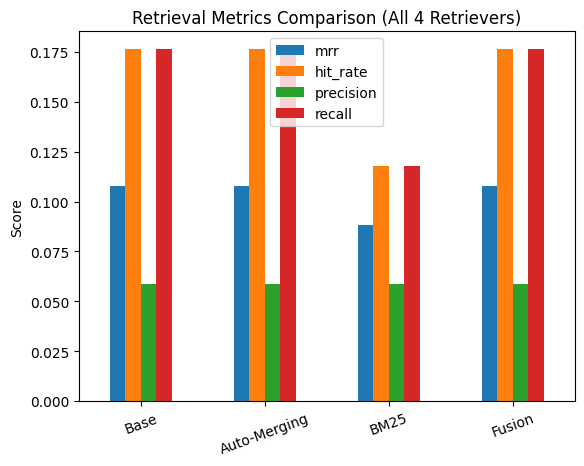

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

def eval_to_mean_df(name, eval_results):
    metric_dicts = [r.metric_vals_dict for r in eval_results]
    dfm = pd.DataFrame(metric_dicts)
    means = dfm.mean(numeric_only=True)
    means.name = name
    return means

summary = pd.concat([
    eval_to_mean_df("Base", base_eval_results),
    eval_to_mean_df("Auto-Merging", auto_eval_results),
    eval_to_mean_df("BM25", bm25_eval_results),
    eval_to_mean_df("Fusion", fusion_eval_results),
], axis=1).T

display(summary)

ax = summary.plot(kind="bar", rot=20)
ax.set_title("Retrieval Metrics Comparison (All 4 Retrievers)")
ax.set_ylabel("Score")
plt.show()